# 02. Data Quality and EDA
**Responsibility:** Keshav - data quality, chronological splitting and EDA.

**Goal:** Read the real data, check it, make chronological splits, and understand the training period.

**Input:** the raw CSV. It downloads from the documented mirror if missing.

**Outputs:** `data/processed/train.csv`, `validation.csv`, `test.csv`, `results/data_quality.json`, `results/splits.csv` and six EDA charts.

This notebook can run in a fresh Python session. It does not need notebook 01 to have executed code.

### Files used in this notebook
- **Read:** `data/raw/creditcard.csv` — the original transaction table.
- **Save for notebook 03:** `data/processed/train.csv`, `data/processed/validation.csv`, `data/processed/test.csv`.
- **Save as evidence:** `results/splits.csv`, `results/data_quality.json` and the six chart files listed below.

Read each explanation, run its code, then read the output. Every path is relative to the main project folder.

## Setup for this notebook
Run from the project root or the `notebooks` folder. The next cell finds the root folder, so saved paths work in either case. Each notebook loads the previous stage's saved files. It does not depend on variables left in another notebook's Python session.

`Path` handles folders, `os.chdir` selects the project root, `pd` handles tables, `np` handles numbers, and `plt` draws charts. The `display` and `Image` tools show tables and pictures.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "CSAI_Project_Instructions_Phase_1_and_Phase_2.pdf").exists())
ROOT = PROJECT / "phase1"
os.chdir(ROOT)
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

## 1. Read the transaction table
**What we do:** Read the recommended ULB/Worldline credit-card dataset.

**Why:** We need examples of real transactions to learn and evaluate patterns.

`read_csv` reads a CSV file into a table called `df`. `head()` shows the first five rows. If the CSV is missing, the next cell downloads the public copy documented by TensorFlow. If you already have it, no download occurs.

**Files in the next cell:** `data/raw/creditcard.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [2]:
data_file = Path("data/raw/creditcard.csv")

if not data_file.exists():
    from urllib.request import urlretrieve
    data_file.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv", data_file)

df = pd.read_csv(data_file)
print("Rows:", len(df), " Columns:", len(df.columns))
display(df.head())

Rows: 284807  Columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### What do the columns mean?
| Column | Simple meaning | How we use it |
|---|---|---|
| Time | Seconds since the first transaction | Put earlier transactions before later ones |
| V1 to V28 | Numerical features hidden by the dataset provider for privacy | Inputs to the GMM |
| Amount | Transaction amount in EUR | Make a less spread-out amount input |
| Class | The correct answer: 0 means legitimate, 1 means fraud | Select legitimate training rows and check results |

A **row** is one transaction. A **feature** is one input describing that transaction. A **label** is the correct answer. We cannot give business meanings to V1-V28 because the original meanings are hidden.

The original file has **284,807 transactions and 492 frauds**. Do not confuse a column called `Class` with a model input.

The provider used **PCA**, which replaces original variables with new numerical combinations. We use its supplied V1-V28 columns and do not run another PCA.

## 2. Check and clean the data
**What we do:** Count missing values and exact repeated rows, then keep the first copy of each exact row.

**Why:** Missing numbers can break model fitting. Exact repeated records can make one observation count several times.

`isna()` finds missing cells. `sum().sum()` adds their count across the whole table. `duplicated()` marks exact repeats. `drop_duplicates()` keeps the first copy. `sort_values("Time")` puts transactions into time order.

**Cleaning assumption:** There is no transaction ID, so we cannot prove that identical rows represent the same real purchase. We document our decision to remove exact repeated records.

In [3]:
raw_rows = len(df)
raw_frauds = int(df["Class"].sum())
missing_cells = int(df.isna().sum().sum())
repeated_rows = int(df.duplicated().sum())

print("Missing cells:", missing_cells)
print("Exact repeated rows:", repeated_rows)
assert missing_cells == 0, "Inspect missing values before continuing."
assert np.isfinite(df.to_numpy()).all(), "Inspect non-finite numbers before continuing."
assert set(df["Class"].unique()) == {0, 1}, "Class must use 0 and 1."

expected_columns = ["Time"] + ["V" + str(i) for i in range(1, 29)] + ["Amount", "Class"]
assert list(df.columns) == expected_columns, "The dataset columns are different."
assert all(pd.api.types.is_numeric_dtype(df[column]) for column in df.columns)
assert (df["Amount"] >= 0).all() and (df["Time"] >= 0).all()
print("Schema, numeric values, labels and nonnegative Amount/Time checks passed.")

df = df.sort_values("Time", kind="stable").drop_duplicates().copy()
print("After cleaning:", len(df), "transactions and", int(df["Class"].sum()), "frauds")

Missing cells: 0
Exact repeated rows: 1081
Schema, numeric values, labels and nonnegative Amount/Time checks passed.
After cleaning: 283726 transactions and 473 frauds


**How to read the output:** There are no missing cells. We remove **1,081 exact repeated rows**. Nineteen of those repeated rows have a fraud label. The cleaned data therefore contains **283,726 transactions and 473 frauds**.

`assert` is a check: it stops execution with a message if a required condition is false. `copy()` gives us a separate table to work with. We keep large amounts and unusual values because unusual transactions are the subject of this project.

## 3. Make three time periods
**What we do:** Use roughly the first 60% for training, the next 20% for validation, and the last 20% for testing.

**Why we need three sets:**
- **Training:** teach the model normal patterns.
- **Validation:** decide how unusual a transaction must be before we create an alert.
- **Test:** check the choices on later transactions.

We split in time order because future transactions should not teach a model that is meant to evaluate the future. The two cutoff times keep transactions with the same timestamp together.

`iloc` reads a row by its position. A condition such as `df["Time"] < train_end` selects rows before that time.

In [4]:
train_end = df["Time"].iloc[int(0.60 * len(df))]
validation_end = df["Time"].iloc[int(0.80 * len(df))]

train = df[df["Time"] < train_end].copy()
validation = df[(df["Time"] >= train_end) & (df["Time"] < validation_end)].copy()
test = df[df["Time"] >= validation_end].copy()

assert train["Time"].max() < validation["Time"].min()
assert validation["Time"].max() < test["Time"].min()

split_table = pd.DataFrame({
    "Set": ["Training", "Validation", "Test"],
    "Transactions": [len(train), len(validation), len(test)],
    "Frauds": [int(train["Class"].sum()), int(validation["Class"].sum()), int(test["Class"].sum())]
})
split_table["Legitimate"] = split_table["Transactions"] - split_table["Frauds"]
split_table["Fraud rate (%)"] = 100 * split_table["Frauds"] / split_table["Transactions"]
display(split_table)

,Set,Transactions,Frauds,Legitimate,Fraud rate (%)
0,Training,170235,342,169893,0.200899
1,Validation,56745,57,56688,0.100449
2,Test,56746,74,56672,0.130406


**How to read the table:** Training contains 342 frauds, validation 57, and test 74. **We will remove the training frauds before fitting the model.** Validation and test keep both classes so we can measure mistakes.

**Fraud rate**, also called **base rate**, means fraud transactions divided by all transactions in that set. Reporting these counts does not use test labels to choose the model.

**Files in the next cell:** `figures/01_split.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

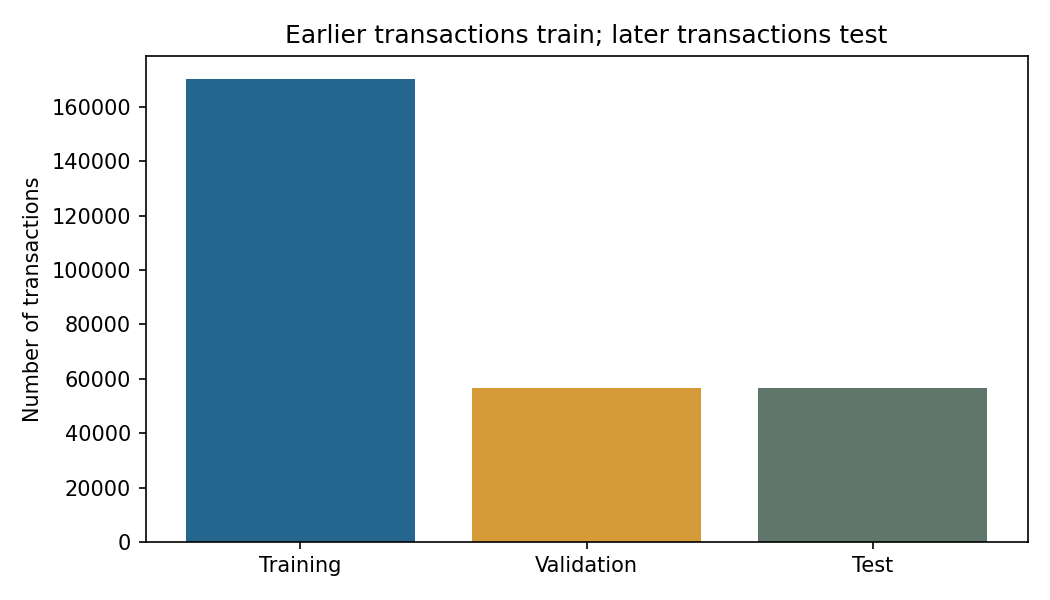

In [5]:
plt.figure(figsize=(7, 4))
plt.bar(split_table["Set"], split_table["Transactions"], color=["#24668d", "#d49a37", "#60766b"])
plt.ylabel("Number of transactions")
plt.title("Earlier transactions train; later transactions test")
plt.tight_layout()
plt.savefig("figures/01_split.png", dpi=150)
display(Image(filename="figures/01_split.png", width=800))
plt.close()

**Chart explanation:** The taller training bar means we use more examples to learn normal patterns. The two smaller bars provide separate periods for choosing the alert cutoff and checking final results.

## 4. EDA: understand the training data
**EDA means Exploratory Data Analysis.** It means using counts and charts to understand the data before fitting the model. We explore training data, so future test examples do not guide our feature decisions.

### 4.1 How rare is fraud?
We count legitimate and fraud transactions separately. `value_counts()` counts each label. `reindex([0, 1])` puts legitimate first and fraud second.

**Files in the next cell:** `figures/02_class_balance.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

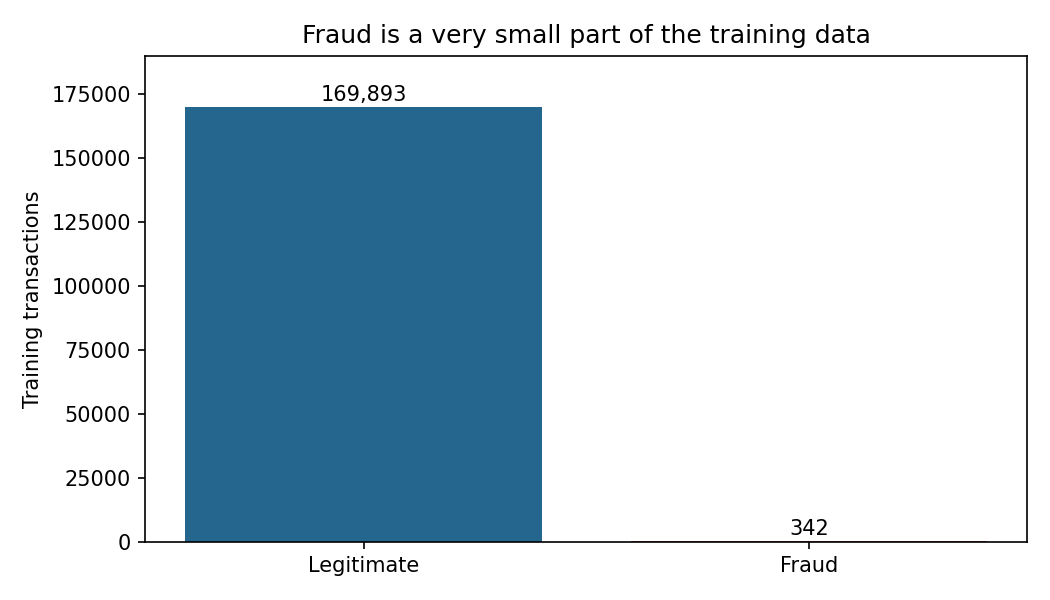

In [6]:
class_counts = train["Class"].value_counts().reindex([0, 1])
plt.figure(figsize=(7, 4))
plt.bar(["Legitimate", "Fraud"], class_counts, color=["#24668d", "#c44945"])
for position, count in enumerate(class_counts):
    plt.text(position, count + 2500, f"{count:,}", ha="center")
plt.ylim(0, 190000)
plt.ylabel("Training transactions")
plt.title("Fraud is a very small part of the training data")
plt.tight_layout()
plt.savefig("figures/02_class_balance.png", dpi=150)
display(Image(filename="figures/02_class_balance.png", width=800))
plt.close()

**Chart explanation:** The fraud bar is tiny because there are only 342 training frauds, compared with 169,893 legitimate transactions. Its small height is the actual imbalance.

**Why accuracy is misleading:** If we said “legitimate” for every test transaction, about 99.87% of answers would be correct, but we would catch **zero frauds**. We will measure fraud found and false alerts instead.

### 4.2 Why change Amount?
Most amounts are small, but a few are very large. This is a **long right tail**. We compare raw Amount with `log(1 + Amount)`.

The log makes large values less spread out. It keeps their order and accepts zero. For example: 0 becomes 0, 9 becomes about 2.30, and 999 becomes about 6.91. We are changing the numerical scale, not deleting expensive transactions.

**Files in the next cell:** `figures/03_amount.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

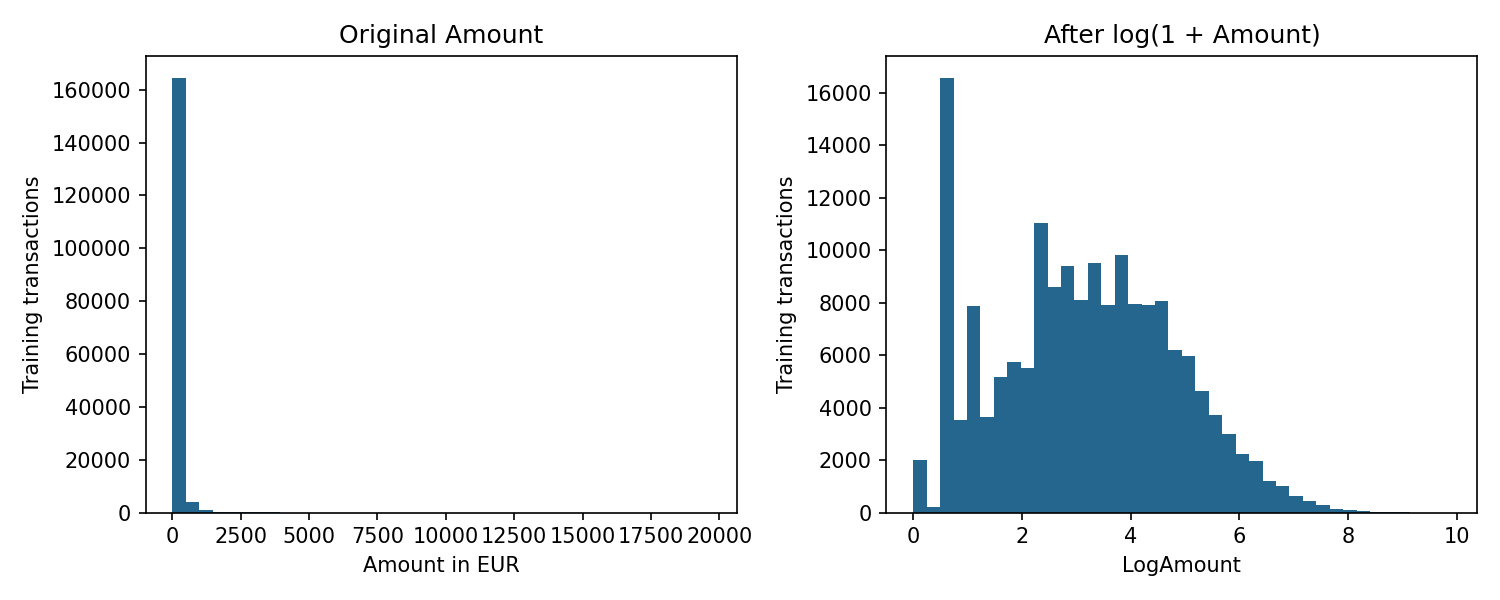

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(train["Amount"], bins=40, color="#24668d")
axes[0].set_title("Original Amount")
axes[0].set_xlabel("Amount in EUR")
axes[0].set_ylabel("Training transactions")

axes[1].hist(np.log1p(train["Amount"]), bins=40, color="#24668d")
axes[1].set_title("After log(1 + Amount)")
axes[1].set_xlabel("LogAmount")
axes[1].set_ylabel("Training transactions")
plt.tight_layout()
plt.savefig("figures/03_amount.png", dpi=150)
display(Image(filename="figures/03_amount.png", width=800))
plt.close()

**Chart explanation:** The first chart packs many transactions near the left edge. The second spreads those values across a smaller numerical range, so their shape is easier to see.

**Plotting code:** `hist` groups values into ranges and counts how many fall in each range. `bins=40` means 40 ranges. The height shows transaction count. `subplots(1, 2)` places two charts next to each other. The last four lines of each chart save a picture, display it, and close the chart.

### 4.3 Does transaction volume change over time?
We divide Time by 3,600 because one hour has 3,600 seconds. `//` means divide and keep the whole-number part. `groupby` collects rows for each hour; `size` counts them.

**Files in the next cell:** `figures/04_time.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

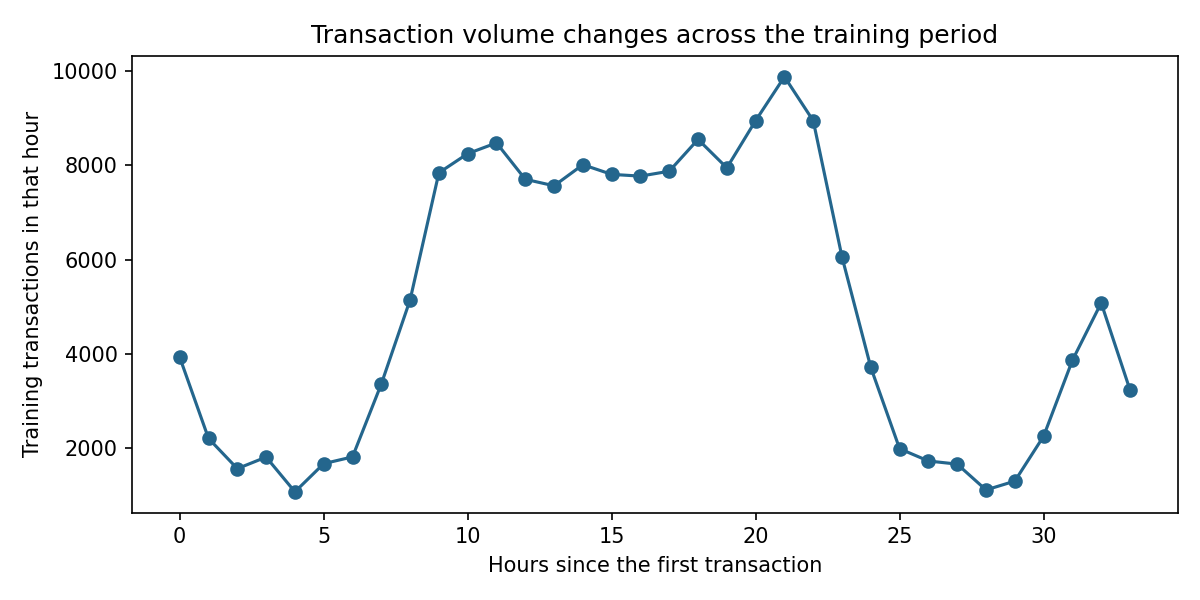

In [8]:
hourly_counts = train.groupby(train["Time"] // 3600).size()
plt.figure(figsize=(8, 4))
plt.plot(hourly_counts.index, hourly_counts.values, marker="o", color="#24668d")
plt.xlabel("Hours since the first transaction")
plt.ylabel("Training transactions in that hour")
plt.title("Transaction volume changes across the training period")
plt.tight_layout()
plt.savefig("figures/04_time.png", dpi=150)
display(Image(filename="figures/04_time.png", width=800))
plt.close()

**Chart explanation:** Some hours contain more transactions than others. We have a short historical recording, so this chart does not prove a pattern that will always repeat. Time remains a splitting tool, not a model input.

### 4.4 Do the two classes overlap?
We show V1 and V2 as a simple two-feature picture. Each dot is one training transaction.

To keep the picture readable, we draw 5,000 legitimate examples and all training frauds. **This sampling affects only the chart. The GMM will still train on every legitimate training row.**

**Files in the next cell:** `figures/05_overlap.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

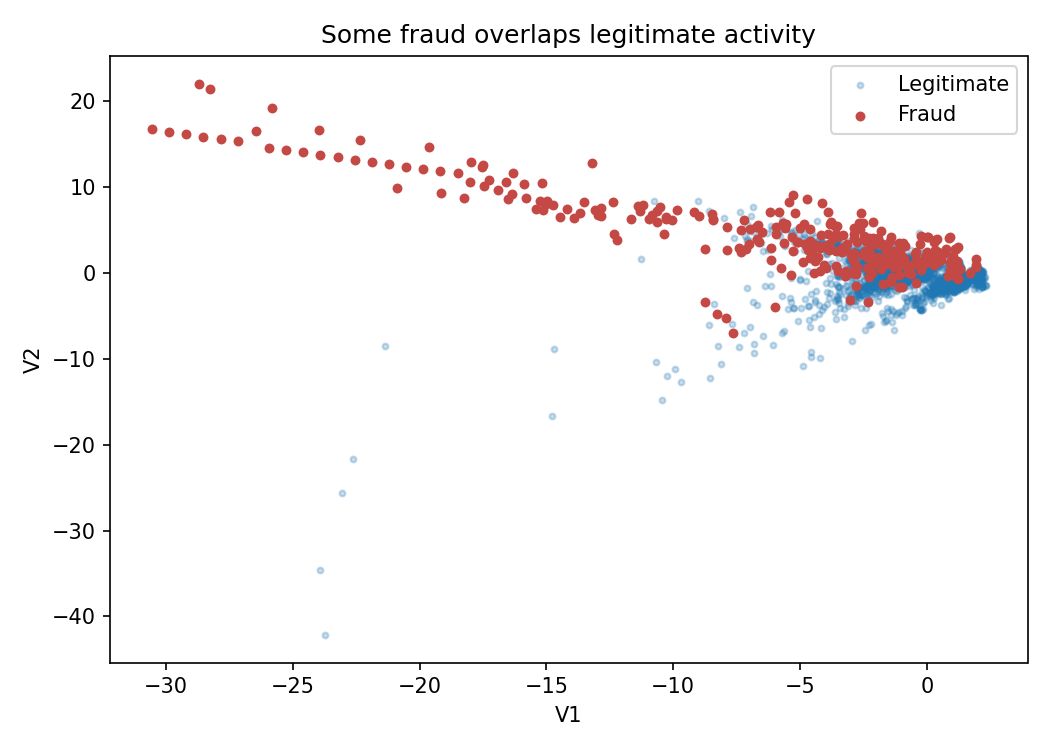

In [9]:
normal_picture = train[train["Class"] == 0].sample(5000, random_state=42)
fraud_picture = train[train["Class"] == 1]

plt.figure(figsize=(7, 5))
plt.scatter(normal_picture["V1"], normal_picture["V2"], s=8, alpha=0.25, label="Legitimate")
plt.scatter(fraud_picture["V1"], fraud_picture["V2"], s=14, color="#c44945", label="Fraud")
plt.xlabel("V1")
plt.ylabel("V2")
plt.title("Some fraud overlaps legitimate activity")
plt.legend()
plt.tight_layout()
plt.savefig("figures/05_overlap.png", dpi=150)
display(Image(filename="figures/05_overlap.png", width=800))
plt.close()

**Chart explanation:** Some fraud points fall near legitimate points. A simple rule on V1 and V2 cannot perfectly separate them. The GMM uses all 29 inputs, but overlap can still produce missed fraud and false alerts. V1 and V2 are anonymous numerical features; we do not know their business meanings.

### 4.5 Do the legitimate input features have relationships?
A correlation heatmap compares pairs of V features in legitimate training rows. Values near 1 or -1 show a strong linear relationship; values near 0 show little linear relationship.

This is a descriptive chart. Low overall correlation does not prove that inputs are independent inside every GMM component. We use diagonal covariance as a simplification, not as a fact established by this chart.

**Files in the next cell:** `figures/11_feature_correlation.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

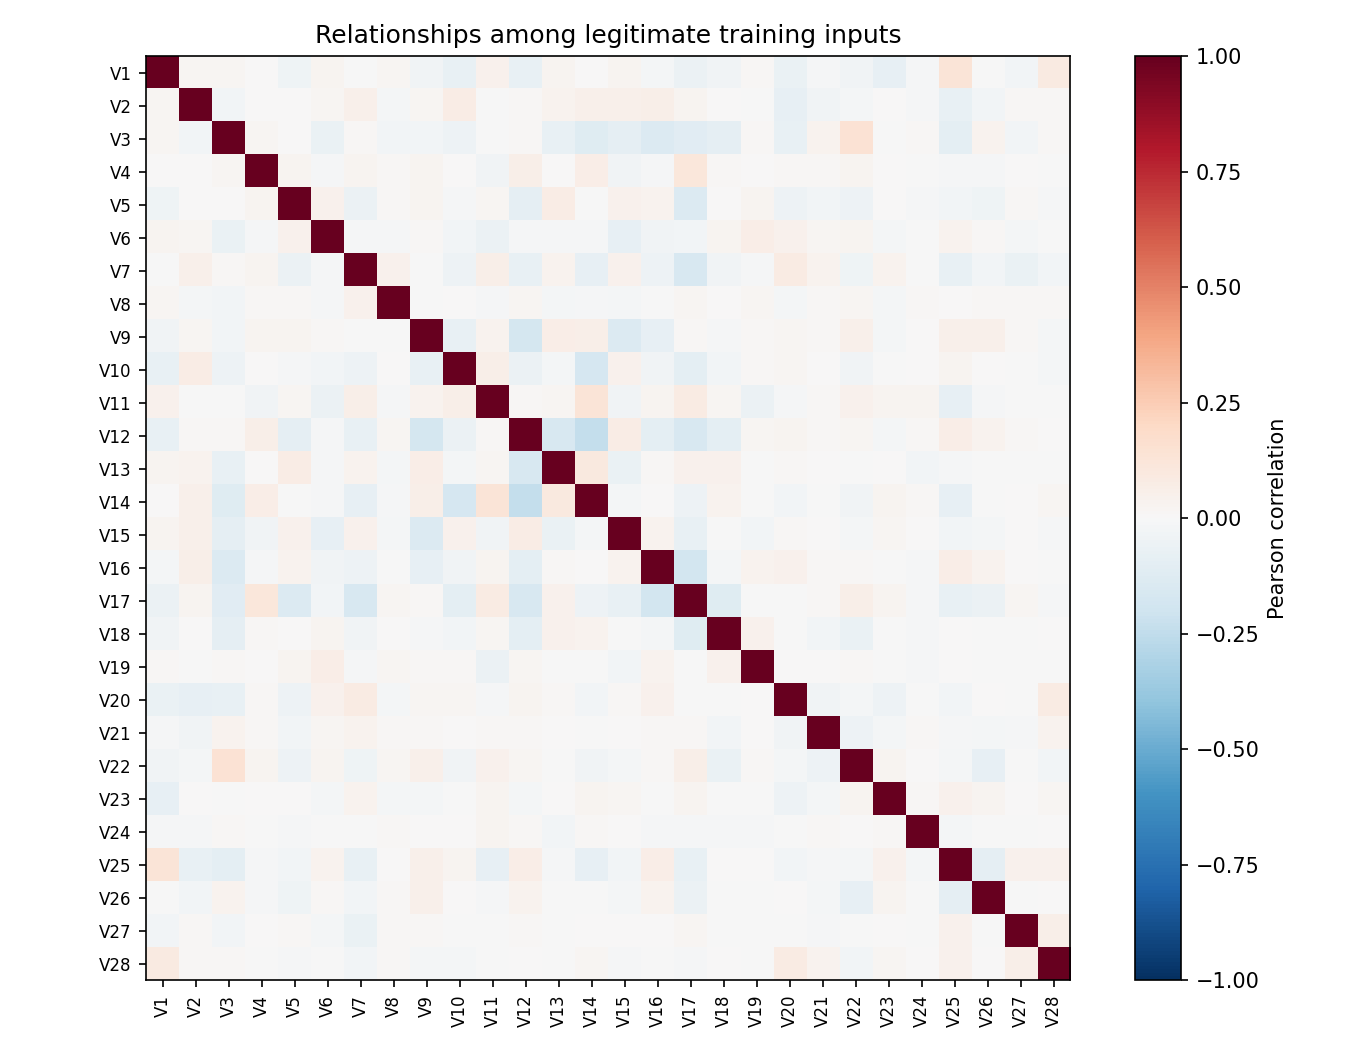

In [10]:
v_columns = ["V" + str(i) for i in range(1, 29)]
correlations = train.loc[train["Class"] == 0, v_columns].corr()
plt.figure(figsize=(9, 7))
plt.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
plt.xticks(range(28), v_columns, rotation=90, fontsize=8)
plt.yticks(range(28), v_columns, fontsize=8)
plt.colorbar(label="Pearson correlation")
plt.title("Relationships among legitimate training inputs")
plt.tight_layout()
plt.savefig("figures/11_feature_correlation.png", dpi=150)
display(Image(filename="figures/11_feature_correlation.png", width=800))
plt.close()

## 5. Save the split tables for notebook 03
`to_csv` saves a table. The next notebook reads these saved tables, so it does not need this notebook's Python variables. All three files preserve both classes; notebook 03 will select legitimate training rows before fitting the scaler.

We also save a short quality record and the input checksum. The checksum identifies the exact raw CSV. `kind="stable"` above keeps the original order of equal timestamps. We preserve the existing row order when saving.

**Files in the next cell:** `data/processed`, `data/processed/test.csv`, `data/processed/train.csv`, `data/processed/validation.csv`, `results/data_quality.json`, `results/splits.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [11]:
import hashlib
Path("data/processed").mkdir(parents=True, exist_ok=True)
train.to_csv("data/processed/train.csv", index=False)
validation.to_csv("data/processed/validation.csv", index=False)
test.to_csv("data/processed/test.csv", index=False)
split_table.to_csv("results/splits.csv", index=False)
quality = {
    "raw_rows": raw_rows, "raw_frauds": raw_frauds,
    "duplicates_removed": repeated_rows, "missing_cells": missing_cells,
    "infinite_cells": 0, "clean_rows": len(df), "clean_frauds": int(df["Class"].sum()),
    "sha256": hashlib.sha256(data_file.read_bytes()).hexdigest(),
    "training_end_exclusive": float(train_end), "validation_end_exclusive": float(validation_end)
}
Path("results/data_quality.json").write_text(json.dumps(quality, indent=2))
print("Saved the split tables. Next: notebook 03.")

Saved the split tables. Next: notebook 03.


**Checkpoint:** 283,726 cleaned rows; split sizes 170,235 / 56,745 / 56,746; fraud counts 342 / 57 / 74. Only the legitimate part of the training period will fit the scaler and GMM.

These tables and class counts are mechanical data checks. They do not use test labels to choose features, model settings or thresholds.

**Next:** `03_Feature_Engineering.ipynb`.